# Homework 7 - Question 5
**Topic:** PCA vs LLE vs t-SNE on digits (0-5)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import LocallyLinearEmbedding, TSNE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

## (a) 

X shape: (1083, 64)  classes: [0 1 2 3 4 5]


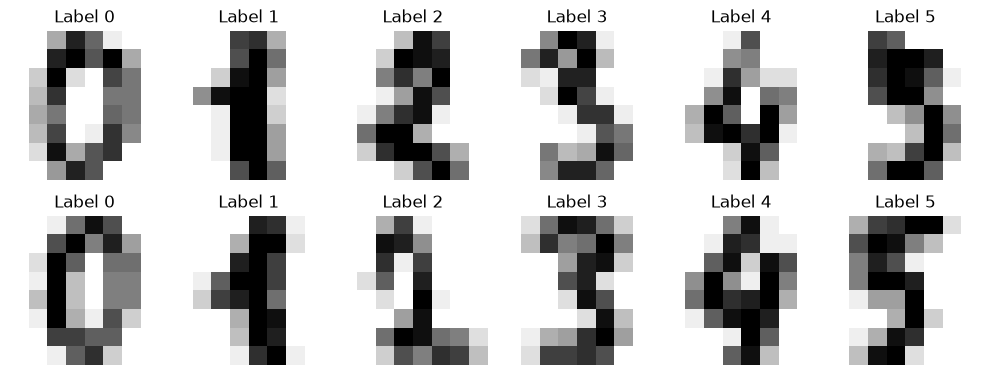

In [2]:
digits = load_digits(n_class=6)
X, y = digits.data, digits.target
print("X shape:", X.shape, " classes:", np.unique(y))

fig, axes = plt.subplots(2, 6, figsize=(10, 4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X[i].reshape(8, 8), cmap='gray_r')
    ax.set_title(f'Label {y[i]}')
    ax.axis('off')
plt.tight_layout()
plt.show()

## (b) 

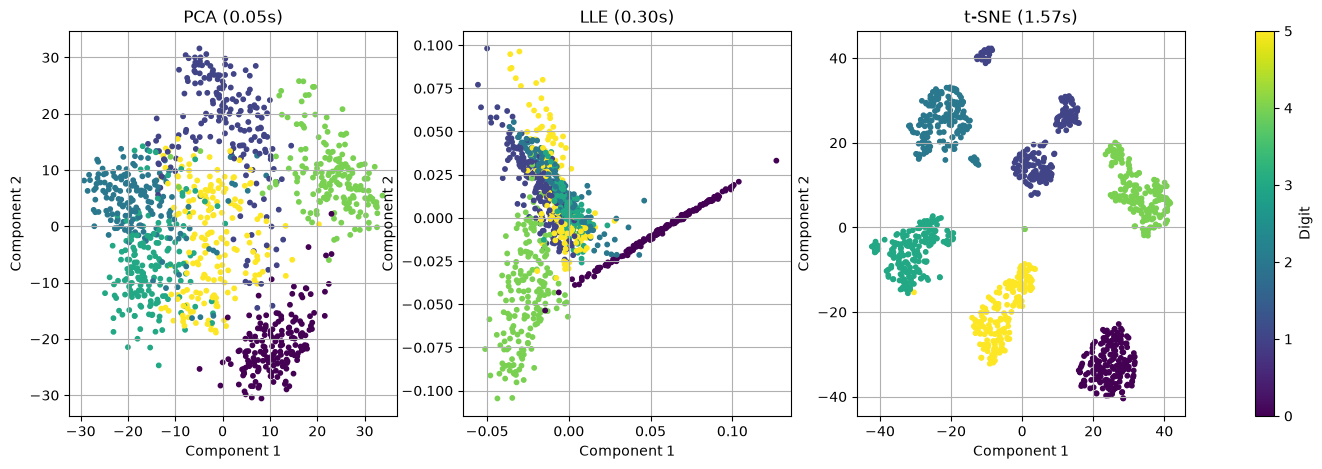

In [3]:
times = {}

t0 = time.time()
X_pca = PCA(n_components=2).fit_transform(X)
times['PCA'] = time.time() - t0

t0 = time.time()
X_lle = LocallyLinearEmbedding(n_neighbors=30, n_components=2, random_state=42).fit_transform(X)
times['LLE'] = time.time() - t0

t0 = time.time()
X_tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X)
times['t-SNE'] = time.time() - t0

embeddings = {'PCA': X_pca, 'LLE': X_lle, 't-SNE': X_tsne}

# Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, Z) in zip(axes, embeddings.items()):
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=y, cmap='viridis', s=10)
    ax.set_title(f'{name} ({times[name]:.2f}s)')
    ax.set_xlabel('Component 1')
    ax.set_ylabel('Component 2')
    ax.grid(True)
fig.colorbar(sc, ax=axes, label='Digit')
plt.show()

## (c) 

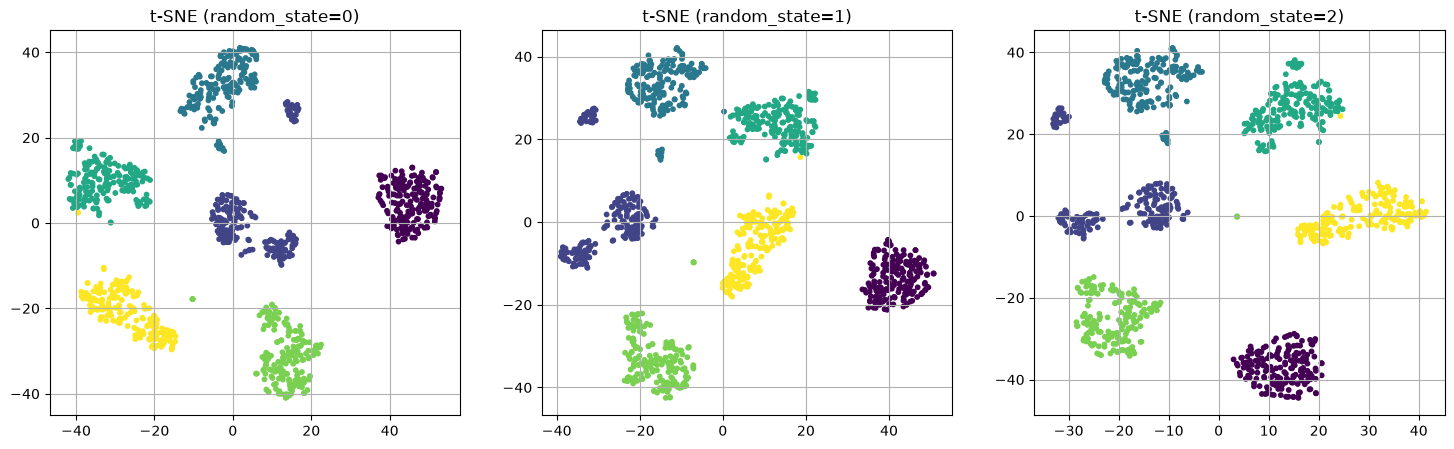

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, seed in zip(axes, [0, 1, 2]):
    Z = TSNE(n_components=2, perplexity=30, init='random', random_state=seed).fit_transform(X)
    ax.scatter(Z[:, 0], Z[:, 1], c=y, cmap='viridis', s=10)
    ax.set_title(f't-SNE (random_state={seed})')
    ax.grid(True)
plt.show()

The positions and orientation of the clusters change between runs  but the cluster shapes and groupings stay basically the same. 

## (d) Discussion
Visually, **t-SNE** separates the digit classes best because its probabilistic Student-$t$ mapping alleviates 2D crowding by repelling dissimilar points while tightly binding local neighbors. Linearity severely limits PCA because projecting 64-dimensional pixel space onto two flat orthogonal axes cannot unfold curved manifold geometry, causing digits 2, 3, and 5 to heavily overlap in the center. Conversely, non-linear manifold learning in LLE over-relies on local reconstruction weights, which distorts the global layout by collapsing classes 1–5 into a tangled central blob and stretching digit 0 into a thin line. Trade-offs exist among interpretability, speed, and separation. For example, PCA is deterministic, highly interpretable, and virtually instantaneous but yields poor separation, whereas t-SNE achieves near-perfect separation at the expense of being slower.

## (e) k-NN (k=5) accuracy on 2D embeddings

In [5]:
for name, Z in embeddings.items():
    Z_train, Z_test, y_train, y_test = train_test_split(Z, y, test_size=0.3, random_state=42, stratify=y)
    knn = KNeighborsClassifier(n_neighbors=5)
    knn.fit(Z_train, y_train)
    print(f"{name:6s} k-NN accuracy: {knn.score(Z_test, y_test):.4f}")

PCA    k-NN accuracy: 0.8462
LLE    k-NN accuracy: 0.6954
t-SNE  k-NN accuracy: 0.9938


t-SNE is the most useful for classification (99.4%), then PCA (84.6%), then LLE (69.5%). This is the same one that looks best visually, since well-separated clusters make it easy for k-NN to pick the right neighbors.